In [ ]:
import csv
import json
from collections import defaultdict

import numpy as np
import rasterio
import torch
from rasterio.warp import Resampling, reproject
from torch import nn
from torch.nn import functional as F

from checkpointing import CHECKPOINT_DIR, SPATIAL_CHECKPOINT_DIR, load_forecaster
from prepare_data import FireDataset, has_fire_observation

import matplotlib.pyplot as plt

ROOT = CHECKPOINT_DIR.parent
COHORT_DIR = ROOT / "data/evaluation/test_epoch050"
WSTS_MANIFEST = json.loads((ROOT / "wsts_manifest.json").read_text())
HORIZON = 32

METRICS = {
    ("active", "ap"): "Active AP",
    ("new", "ap"): "New AP",
    ("burned", "iou"): "Burned IoU",
    ("burned", "ap"): "Burned AP",
}

In [2]:
def load_wsts_input(path):
    with rasterio.open(path) as src:
        x = src.read().astype(np.float32)
    x[-1] = np.floor(np.nan_to_num(x[-1], nan=0) / 100)
    active = (x[-1:] > 0).astype(np.float32)
    x[[7, 13, 19]] = np.sin(np.deg2rad(x[[7, 13, 19]]))
    means = np.asarray(WSTS_MANIFEST['means'], dtype=np.float32)[:, None, None]
    stds = np.asarray(WSTS_MANIFEST['stds'], dtype=np.float32)[:, None, None]
    x = np.nan_to_num((x - means) / stds, nan=0)
    # Exactly reproduce the authors' one-hot ordering and missing-class behavior.
    landcover = np.eye(17, dtype=np.float32)[x[16].astype(int) - 1].transpose(2, 0, 1)
    return np.concatenate([x[:16], landcover, x[17:], active])


class WSTSForecast(nn.Module):

    def __init__(self, LTAE2d, TemporalAggregator):
        super().__init__()
        import segmentation_models_pytorch as smp
        self.model = smp.Unet(encoder_name='resnet18', encoder_weights=None, in_channels=40, classes=1)
        self.ltae = LTAE2d(in_channels=512, n_head=16, d_k=4, mlp=[256, 512], dropout=0.2, d_model=256, T=1000, return_att=True, positional_encoding=True)
        self.temporal_aggregator = TemporalAggregator(mode='att_group')


def load_wsts_model(device='cuda'):
    from utae.ltae import LTAE2d
    from utae.utae import Temporal_Aggregator
    net = WSTSForecast(LTAE2d, Temporal_Aggregator)
    net.load_state_dict(torch.load(CHECKPOINT_DIR / 'baselines/wsts_fold1.pt', map_location='cpu', weights_only=True))
    return net.to(device).eval()

In [3]:
def score(p, target):
    y = target.astype(bool)
    b = p >= 0.5
    tp, fp, fn = (int(np.count_nonzero(v)) for v in (b & y, b & ~y, ~b & y))
    ap = None
    if y.any():
        order = np.argsort(-p, kind='stable')
        ends = np.r_[np.flatnonzero(np.diff(p[order])), len(p) - 1]
        hits = np.cumsum(y[order], dtype=np.int64)[ends]
        ap = float(np.sum(np.diff(np.r_[0, hits]) * hits / (ends + 1)) / y.sum())
    return dict(ap=ap, tp=tp, fp=fp, fn=fn, pixels=len(p), positives=int(y.sum()))


def score_predictions(rows, predictions, targets, footprint, **meta):
    for head, target in targets.items():
        values = predictions[head][footprint]
        if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise ValueError(f"Invalid probabilities for {meta}, {head}")
        stats = score(values, target)
        union = stats["tp"] + stats["fp"] + stats["fn"]
        rows.append(dict(**meta, output=head, iou=stats["tp"] / union if union else None, **stats))


def averages(rows, *, by_lead=False):
    groups = defaultdict(lambda: defaultdict(list))
    for row in rows:
        for output, metric in METRICS:
            if row["output"] == output and row[metric] is not None:
                key = (row["model"], output, metric)
                if by_lead:
                    key += (row["lead"],)
                groups[key][row["fire"]].append(row[metric])
    return {key: np.mean([np.mean(scores) for scores in fires.values()])
            for key, fires in groups.items()}

In [4]:
class FeatureHistory:
    # Encode each day once and reuse its spatial features as history grows.

    def __init__(self, encode, first_frame):
        self.encode = encode
        first = encode(first_frame)
        self.banks = [part.new_empty((1, HORIZON, *part.shape[1:])) for part in first]
        self._write(0, first)

    def _write(self, index, features):
        for bank, feature in zip(self.banks, features, strict=True):
            bank[:, index].copy_(feature)

    def append(self, index, frame):
        self._write(index, self.encode(frame))

    def prefix(self, length):
        return [bank[:, :length] for bank in self.banks]


def fireforecaster_rollout(net, image, device):
    valid = np.isfinite(image)
    channels = np.concatenate((np.where(valid, image, 0), valid)).astype(np.float32)
    first_frame = torch.from_numpy(channels).to(device)[None]
    history = FeatureHistory(
        lambda frame: net.encoder._encode_day(frame, keep_on_gpu=True), first_frame
    )
    if net.memory is not None:
        net.memory.reset_memory()

    dates = torch.arange(HORIZON, dtype=torch.float32, device=device)
    for lead in range(1, HORIZON + 1):
        positions = (dates[:lead] - dates[lead - 1])[None]
        padding = torch.zeros_like(positions, dtype=torch.bool)
        bottleneck, skips = net.encoder._aggregate_maps(history.prefix(lead), positions, padding)
        bottleneck = net.apply_memory(bottleneck, first_frame[:, 27:29], update_memory=(lead == 1))
        output = net.output(net.decoder(bottleneck, skips))
        yield {name: tensor[0, 0].cpu().numpy()
               for name, tensor in zip(("active", "burned", "new"), output, strict=True)}
        if lead < HORIZON:
            next_frame = first_frame.clone()
            next_frame[:, 27:28], next_frame[:, 28:29] = output[:2]
            next_frame[:, 56:58] = 1
            history.append(lead, next_frame)


def wsts_rollout(net, first_frame, align, initial_burned, device):
    height, width = first_frame.shape[-2:]

    def encode(frame):
        tensor = torch.from_numpy(frame).to(device)[None]
        return net.model.encoder(F.pad(tensor, (0, (-width) % 32, 0, (-height) % 32)))

    history = FeatureHistory(encode, first_frame)
    previous_burned = initial_burned
    mean, std = (WSTS_MANIFEST[key][22] for key in ("means", "stds"))
    detected = first_frame[39] > 0
    detection_hour = float(first_frame[38][detected].mean()) * std + mean if detected.any() else float(mean)
    for lead in range(1, HORIZON + 1):
        maps = history.prefix(lead)
        positions = torch.arange(lead, device=device)[None]
        bottleneck, attention = net.ltae(maps[-1], batch_positions=positions)
        attention = attention.contiguous()
        skips = [net.temporal_aggregator(level, attn_mask=attention) for level in maps[1:-1]]
        decoded = net.model.decoder(maps[0][:, 0], *skips, bottleneck)
        active = net.model.segmentation_head(decoded).sigmoid()[0, 0, :height, :width].cpu().numpy()
        active_aligned = align(active)
        new = (1 - previous_burned) * active_aligned
        previous_burned = previous_burned + new
        yield dict(active=active_aligned, new=new, burned=previous_burned)
        if lead < HORIZON:
            next_frame = first_frame.copy()
            next_frame[39] = active
            next_frame[38] = (detection_hour * active - mean) / std
            history.append(lead, next_frame)

In [5]:
def select_cohort():
    manifest = json.loads((COHORT_DIR / 'cohort.json').read_text())
    test = set((ROOT / "test_fires.txt").read_text().split())
    development = set((ROOT / "train_fires.txt").read_text().split())
    development.update((ROOT / "val_fires.txt").read_text().split())
    choices = sorted(manifest, key=lambda item: -sum(
        item["verification"][key] for key in ("ts_matches", "wsts_matches")
    ))
    by_archive_fire = {}
    for item in choices:
        fire = item["fire"]
        if fire not in test or fire in development:
            raise ValueError(f"{fire} is outside the reserved test split")
        if not item["inputs"]:
            raise ValueError(f"{fire} is missing its first WSTS input")
        by_archive_fire.setdefault(item["archive_fire"], item)
    return sorted(by_archive_fire.values(), key=lambda item: item["fire"])


def load_case(item):
    dataset = FireDataset(ROOT / "data/raw_test/ts-satfire" / item["fire"], require_daily=False)
    issue = dataset.dates[0]
    if len(dataset.dates) < 2:
        raise ValueError(f"{item['fire']} has no targets after issuance")
    image = dataset.read_day(0)
    source = COHORT_DIR / "wsts_sources" / item["inputs"][0]["name"]
    if source.stem != str(issue):
        raise ValueError(f"{item['fire']} has a mismatched first WSTS date")
    with rasterio.open(source) as src:
        shape, crs, affine = src.shape, src.crs, src.transform

    def align(values, method=Resampling.bilinear):
        result = np.full((dataset.height, dataset.width), np.nan, np.float32)
        reproject(values, result, src_transform=affine, src_crs=crs,
                  dst_transform=dataset.transform, dst_crs=dataset.crs,
                  dst_nodata=np.nan, resampling=method)
        return result

    footprint = np.isfinite(align(np.ones(shape, np.float32), Resampling.nearest))
    if not footprint.any() or not has_fire_observation(np.isfinite(image)):
        raise ValueError(f"{item['fire']} lacks shared coverage or a usable first observation")

    targets = {}
    for index, date in enumerate(dataset.dates[1:], 1):
        lead = int((date - issue).astype(int))
        if lead > HORIZON:
            break
        active, burned = dataset.active[index], dataset.burned[index]
        targets[lead] = dict(active=active[footprint], burned=burned[footprint])
        if (date - dataset.dates[index - 1]).astype(int) == 1:
            targets[lead]["new"] = (burned & ~dataset.burned[index - 1])[footprint]

    active = dataset.active[0].astype(np.float32)
    burned = dataset.burned[0].astype(np.float32)
    return image, load_wsts_input(source), align, footprint, targets, active, burned, issue


@torch.inference_mode()
def run_benchmark():
    if not torch.cuda.is_available():
        raise RuntimeError("Run the benchmark in a CUDA-enabled PyTorch kernel")
    device = torch.device("cuda")
    torch.backends.cudnn.benchmark = False
    torch.set_float32_matmul_precision("highest")
    torch.backends.cudnn.allow_tf32 = False

    first = load_forecaster(CHECKPOINT_DIR / "baseline_1.pt", device, use_memory=False)
    epoch_50 = SPATIAL_CHECKPOINT_DIR / "epoch_050.pt"
    spatial = load_forecaster(epoch_50, device)
    bypass = load_forecaster(epoch_50, device, use_memory=False)
    wsts = load_wsts_model(device)

    rows = []
    for item in select_cohort():
        image, wsts_frame, align, footprint, targets, active, burned, issue = load_case(item)
        persistence = dict(active=active, burned=burned, new=np.zeros_like(burned))
        rollouts = {
            "persistence": (persistence for _ in range(HORIZON)),
            "wsts": wsts_rollout(wsts, wsts_frame, align, burned, device),
            "baseline_1_no_snn": fireforecaster_rollout(first, image, device),
            "epoch_050": fireforecaster_rollout(spatial, image, device),
            "epoch_050_no_snn": fireforecaster_rollout(bypass, image, device),
        }
        for model, forecast in rollouts.items():
            for lead, prediction in enumerate(forecast, 1):
                if lead in targets:
                    score_predictions(
                        rows, prediction, targets[lead], footprint,
                        fire=item["fire"], model=model, condition="full_history", lead=lead,
                        target_date=str(issue + np.timedelta64(lead, "D")),
                    )
        print(f"{item['fire']}: scored {len(targets)} of {HORIZON} forecast days", flush=True)
    return rows

US_2021_CA3658211879520210912: scored 32 of 32 forecast days
US_2021_ID4558511544420210705: scored 31 of 32 forecast days
US_2021_ID4762711608320210708: scored 31 of 32 forecast days
US_2021_MT4579011310120210708: scored 31 of 32 forecast days
US_2021_WA4879111827120210805: scored 25 of 32 forecast days
Model                     Active AP      New AP  Burned IoU   Burned AP
Persistence                   1.41%       0.11%      16.42%      18.43%
WSTS                          1.83%       0.40%       5.53%      21.99%
Initial Baseline              7.27%       2.36%      21.36%      28.72%
Epoch 50                      6.16%       1.88%      19.09%      36.17%
Epoch 50 (SNN off)            5.83%       1.52%      19.02%      29.43%


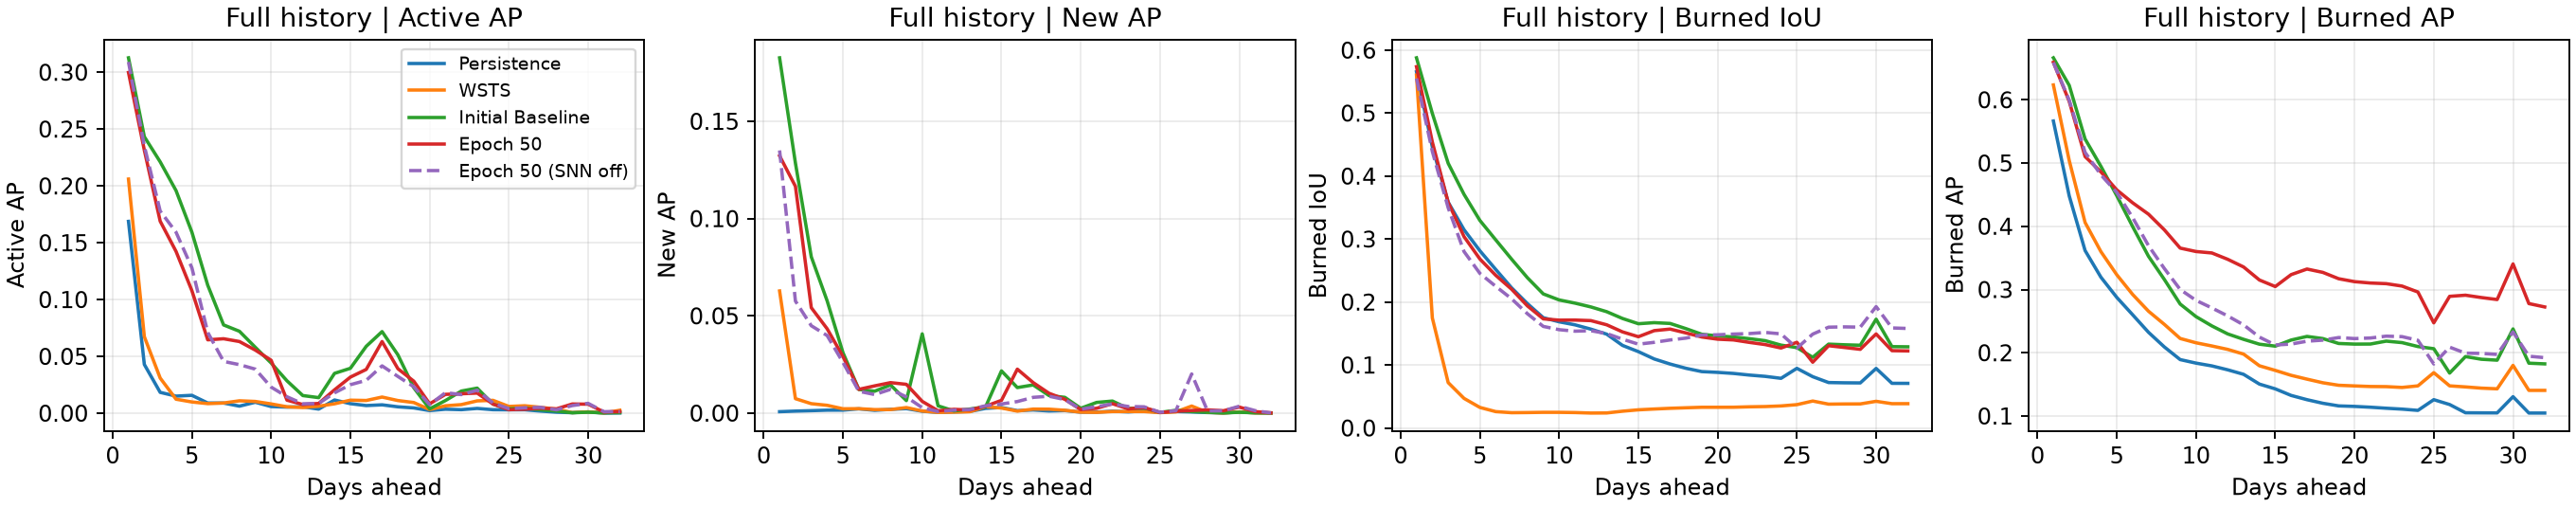

In [ ]:
rows = run_benchmark()
with open("scores.csv", "w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

names = {
    "persistence": "Persistence",
    "wsts": "WSTS",
    "baseline_1_no_snn": "Initial Baseline",
    "epoch_050": "Epoch 50",
    "epoch_050_no_snn": "Epoch 50 (SNN off)",
}
means = averages(rows)
print(f"{'Model':<23} " + " ".join(f"{label:>11}" for label in METRICS.values()))
for model, name in names.items():
    values = [means.get((model, *metric), float("nan")) for metric in METRICS]
    print(f"{name:<23} " + " ".join(f"{value:>11.2%}" for value in values))

by_lead = averages(rows, by_lead=True)
leads = range(1, HORIZON + 1)
with plt.style.context("default"):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.15), sharex=True, layout="constrained")
    for ax, (metric, label) in zip(axes, METRICS.items(), strict=True):
        for model, name in names.items():
            values = [by_lead.get((model, *metric, lead)) for lead in leads]
            ax.plot(leads, values, label=name, linestyle="--" if model == "epoch_050_no_snn" else "-")
        ax.set(title=f"Full history | {label}", xlabel="Days ahead", ylabel=label)
        ax.grid(alpha=0.25)
    axes[0].legend(loc="upper right", fontsize=8)
    fig.savefig("day1_32day_metric_grid.png", dpi=170)
    plt.show()